# Feature Engineering

## Set-up

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [2]:
# Load Data
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_PATH = PROJECT_ROOT / "outputs"

train = pd.read_csv(PROCESSED_DATA_PATH / "train.csv")
test = pd.read_csv(PROCESSED_DATA_PATH / "test.csv")

train

,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,...,job,people_liable,telephone,foreign_worker,original_label,credit_risk,gender_group,age_group,log1p_credit_amount,log1p_duration_months
0,1,0 to <200 DM,48,Existing credits paid duly so far,Radio/television,5951,<100 DM,1 to <4 years,2,Female: divorced/separated/married,...,Skilled employee/official,1,No / none,Yes,2,1,Female,<25,8.691483,3.891820
1,2,No checking account,12,Critical account / other credits elsewhere,Education,2096,<100 DM,4 to <7 years,2,Male: single,...,Unskilled resident,2,No / none,Yes,1,0,Male,45-54,7.648263,2.564949
2,3,<0 DM,42,Existing credits paid duly so far,Furniture/equipment,7882,<100 DM,4 to <7 years,2,Male: single,...,Skilled employee/official,2,No / none,Yes,1,0,Male,45-54,8.972464,3.761200
3,4,<0 DM,24,Past repayment delay,New car,4870,<100 DM,1 to <4 years,3,Male: single,...,Skilled employee/official,2,No / none,Yes,2,1,Male,45-54,8.491055,3.218876
4,5,No checking account,36,Existing credits paid duly so far,Education,9055,Unknown / no savings account,1 to <4 years,2,Male: single,...,Unskilled resident,2,Registered in customer name,Yes,1,0,Male,35-44,9.111183,3.610918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,993,<0 DM,36,Existing credits paid duly so far,Furniture/equipment,3959,<100 DM,Unemployed,4,Male: single,...,Management/self-employed/highly qualified,1,Registered in customer name,Yes,1,0,Male,25-34,8.283999,3.610918
796,995,No checking account,12,Existing credits paid duly so far,Furniture/equipment,1736,<100 DM,4 to <7 years,3,Female: divorced/separated/married,...,Unskilled resident,1,No / none,Yes,1,0,Female,25-34,7.459915,2.564949
797,996,<0 DM,30,Existing credits paid duly so far,Used car,3857,<100 DM,1 to <4 years,4,Male: divorced/separated,...,Management/self-employed/highly qualified,1,Registered in customer name,Yes,1,0,Male,35-44,8.257904,3.433987
798,998,<0 DM,45,Existing credits paid duly so far,Radio/television,1845,<100 DM,1 to <4 years,4,Male: single,...,Skilled employee/official,1,Registered in customer name,Yes,2,1,Male,<25,7.520776,3.828641


In [3]:
# Copy the training dataset first
train_fe = train.copy()

## Creating Features

### Feature 1: Monthly Principal Repayment Proxy



In [4]:
train_fe["monthly_principal_proxy"] = (
    train_fe["credit_amount"] / train_fe["duration_months"]
)

### Feature 2: Large Loan & Short Employment

In [5]:
credit_q75 = train["credit_amount"].quantile(0.75)

train_fe["large_loan_short_employment"] = (
    (train_fe["credit_amount"] > credit_q75) &
    (train_fe["employment_since"].isin([
        "Unemployed",
        "<1 year"
    ]))
).astype(int)

### Feature 3: Large Loan & Low Savings

In [6]:
train_fe["large_loan_low_savings"] = (
    (train_fe["credit_amount"] > credit_q75) &
    (train_fe["savings_account"] == "<100 DM")
).astype(int)

### Feature 4: Low Savings & Negative Checking Balance

In [7]:
train_fe["low_savings_negative_checking"] = (
    (train_fe["savings_account"] == "<100 DM") &
    (train_fe["checking_account"] == "<0 DM")
).astype(int)

### Feature 5: Loan Amount Per Existing Credit

In [8]:
train_fe["loan_per_credit"] = (
    train_fe["credit_amount"] / train_fe["existing_credits"]
)

### Feature 6: Has Other Installment Plan

In [9]:
train_fe["has_other_installment_plan"] = (
    train_fe["other_installment_plans"] != "No / none"
).astype(int)

### Feature 7: Poor Credit History & Multiple Credits

In [10]:
poor_history = ["Past repayment delay", "Critical account / other credits elsewhere"]

train_fe["poor_history_multiple_credits"] = (
    (train_fe["credit_history"].isin(poor_history)) &
    (train_fe["existing_credits"] > 1)
).astype(int)

### Feature 8: Long Duration & Large Loan

In [11]:
duration_q75 = train["duration_months"].quantile(0.75)

train_fe["long_duration_large_loan"] = (
    (train_fe["duration_months"] > duration_q75) &
    (train_fe["credit_amount"] > credit_q75)
).astype(int)

## Inspecting Engineered Features

In [12]:
engineered_features = [
    "monthly_principal_proxy",
    "large_loan_short_employment",
    "large_loan_low_savings",
    "low_savings_negative_checking",
    "loan_per_credit",
    "has_other_installment_plan",
    "poor_history_multiple_credits",
    "long_duration_large_loan"
]

display(train_fe[engineered_features].head())

,monthly_principal_proxy,large_loan_short_employment,large_loan_low_savings,low_savings_negative_checking,loan_per_credit,has_other_installment_plan,poor_history_multiple_credits,long_duration_large_loan
0,123.979167,0,1,0,5951.0,0,0,1
1,174.666667,0,0,0,2096.0,0,0,0
2,187.666667,0,1,1,7882.0,0,0,1
3,202.916667,0,1,1,2435.0,0,1,0
4,251.527778,0,0,0,9055.0,0,0,1


In [13]:
# Ensure no missing or infinite values
print("Missing values:")
display(train_fe[engineered_features].isna().sum())

print("Infinite values:")
display(
    pd.Series(
        np.isinf(train_fe[engineered_features]).sum(),
        index=engineered_features
    )
)

Missing values:


monthly_principal_proxy          0
large_loan_short_employment      0
large_loan_low_savings           0
low_savings_negative_checking    0
loan_per_credit                  0
has_other_installment_plan       0
poor_history_multiple_credits    0
long_duration_large_loan         0
dtype: int64

Infinite values:


monthly_principal_proxy          0
large_loan_short_employment      0
large_loan_low_savings           0
low_savings_negative_checking    0
loan_per_credit                  0
has_other_installment_plan       0
poor_history_multiple_credits    0
long_duration_large_loan         0
dtype: int64

### Check Distributions

,monthly_principal_proxy,loan_per_credit
count,800.000000,800.000000
mean,168.976272,2647.329271
std,160.634570,2543.305805
min,25.250000,169.000000
25%,87.766667,1036.375000
50%,129.895833,1862.500000
75%,208.369792,3333.750000
max,2482.666667,18424.000000


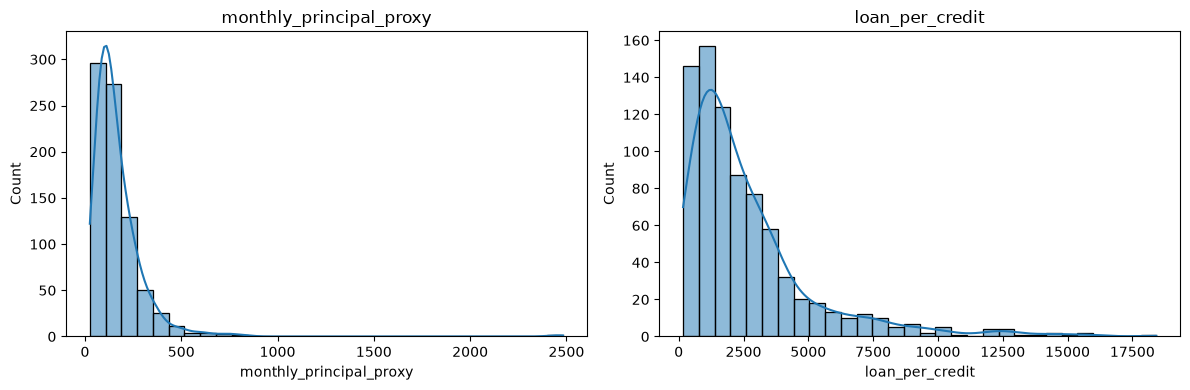

In [14]:
# Continuous Features
continuous_features = ["monthly_principal_proxy", "loan_per_credit"]

display(train_fe[continuous_features].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, continuous_features):
    sns.histplot(
        data=train_fe,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

Both distributions are heavily right-skewed, with most borrowers having relatively small monthly principal repayment amounts and loans per credit.

In [15]:
# Binary Features
binary_features = [
    col for col in engineered_features
    if col not in continuous_features
]

binary_summary = pd.DataFrame({
    "Count (1)": train_fe[binary_features].sum(),
    "Percentage (1)": train_fe[binary_features].mean() * 100
})

display(binary_summary.round(2))

,Count (1),Percentage (1)
large_loan_short_employment,48,6.00
large_loan_low_savings,117,14.62
low_savings_negative_checking,180,22.50
has_other_installment_plan,151,18.88
poor_history_multiple_credits,221,27.62
long_duration_large_loan,122,15.25


All features except large_loan_short_employment occur in 15-28% of training observations.

In [16]:
summary = train_fe.groupby("large_loan_short_employment")["credit_risk"].agg(
    count="count",
    bad_credit_rate="mean"
)

display(summary.round(3))

,count,bad_credit_rate
large_loan_short_employment,,
0,752,0.290
1,48,0.458


In [17]:
pd.crosstab(
    train_fe["large_loan_short_employment"],
    train_fe["credit_risk"],
    margins=True
)

credit_risk,0,1,All
large_loan_short_employment,,,
0,534,218,752
1,26,22,48
All,560,240,800


The large_loan_short_employment feature identifies borrowers requesting loans above the 75th percentile of credit amount who are unemployed or have less than one year of employment tenure. Although only 6% of training observations satisfy this condition, their observed bad-credit rate is 45.8%, compared with 29.0% for other borrowers. This suggests a potential association between the interaction and credit risk, motivating its inclusion as a candidate predictor. 

### Fixes

In [18]:
train_fe["log_monthly_principal_proxy"] = np.log1p(
    train_fe["monthly_principal_proxy"]
)

train_fe["log_loan_per_credit"] = np.log1p(
    train_fe["loan_per_credit"]
)

skew_comparison = pd.DataFrame({
    "Original": train_fe[
        ["monthly_principal_proxy", "loan_per_credit"]
    ].skew().values,
    "Log-transformed": train_fe[
        ["log_monthly_principal_proxy", "log_loan_per_credit"]
    ].skew().values
}, index=["monthly_principal_proxy", "loan_per_credit"])

display(skew_comparison)

,Original,Log-transformed
monthly_principal_proxy,7.932746,0.444044
loan_per_credit,2.405388,0.030845


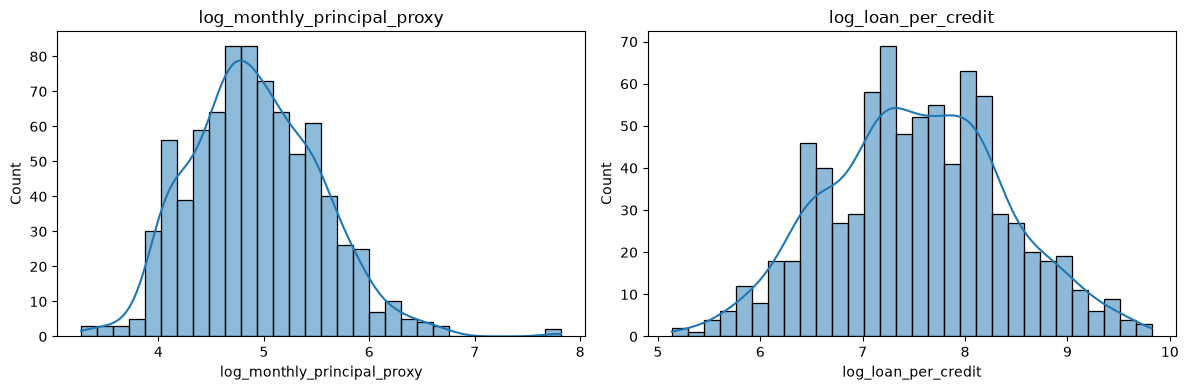

In [19]:
log_features = ["log_monthly_principal_proxy", "log_loan_per_credit"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, log_features):
    sns.histplot(
        data=train_fe,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

Applying a log(1+x) transformation reduced the skewness of monthly principal proxy and loan per existing credit.

## Encoding

In [20]:
# Numerical features
numeric_features = [
    "existing_credits",
    "people_liable",
    "log_monthly_principal_proxy",
    "log_loan_per_credit",
    "log1p_credit_amount",
    "log1p_duration_months"
]

# Categorical features
categorical_features = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_since",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
    "installment_rate",
    "residence_since"
]

# Binary engineered features
binary_features = [
    "large_loan_short_employment",
    "large_loan_low_savings",
    "low_savings_negative_checking",
    "has_other_installment_plan",
    "poor_history_multiple_credits",
    "long_duration_large_loan"
]

all_features = numeric_features + categorical_features + binary_features

X_train = train_fe[all_features]
y_train = train_fe["credit_risk"]

print("Number of input features:", len(all_features))
print("Training shape:", X_train.shape)

Number of input features: 26
Training shape: (800, 26)


In [21]:
# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
    ("binary", "passthrough", binary_features)
])

In [22]:
# Transform data
X_train_processed = preprocessor.fit_transform(X_train)

print("Original shape:", X_train.shape)
print("Processed shape:", X_train_processed.shape)

Original shape: (800, 26)
Processed shape: (800, 70)


### Inspect Encoded Dataset

In [23]:
# Get feature names
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

display(pd.DataFrame({
    "feature_name": feature_names
}))

Number of processed features: 70


,feature_name
0,num__existing_credits
1,num__people_liable
2,num__log_monthly_principal_proxy
3,num__log_loan_per_credit
4,num__log1p_credit_amount
...,...
65,binary__large_loan_low_savings
66,binary__low_savings_negative_checking
67,binary__has_other_installment_plan
68,binary__poor_history_multiple_credits


In [24]:
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

display(X_train_processed_df.head())

,num__existing_credits,num__people_liable,num__log_monthly_principal_proxy,num__log_loan_per_credit,num__log1p_credit_amount,num__log1p_duration_months,cat__checking_account_0 to <200 DM,cat__checking_account_<0 DM,cat__checking_account_>=200 DM / salary assignment >=1 year,cat__checking_account_No checking account,...,cat__residence_since_1,cat__residence_since_2,cat__residence_since_3,cat__residence_since_4,binary__large_loan_short_employment,binary__large_loan_low_savings,binary__low_savings_negative_checking,binary__has_other_installment_plan,binary__poor_history_multiple_credits,binary__long_duration_large_loan
0,-0.712917,-0.434405,-0.154850,1.370626,1.152417,1.717077,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.712917,2.302002,0.400080,0.149435,-0.180267,-0.673560,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.712917,2.302002,0.516454,1.699542,1.511363,1.481737,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,1.052821,2.302002,0.643156,0.324848,0.896376,0.504626,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
4,-0.712917,2.302002,0.991673,1.861926,1.688572,1.210972,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [25]:
print("Missing values:",
      X_train_processed_df.isna().sum().sum())

print("Infinite values:",
      np.isinf(X_train_processed_df.to_numpy()).sum())

print("Processed shape:",
      X_train_processed_df.shape)

display(
    X_train_processed_df[
        [col for col in feature_names if col.startswith("num__")]
    ].describe().round(3)
)

Missing values: 0
Infinite values: 0
Processed shape: (800, 70)


,num__existing_credits,num__people_liable,num__log_monthly_principal_proxy,num__log_loan_per_credit,num__log1p_credit_amount,num__log1p_duration_months
count,800.000,800.000,800.000,800.000,800.000,800.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001
min,-0.713,-0.434,-2.698,-2.792,-2.766,-2.395
25%,-0.713,-0.434,-0.713,-0.674,-0.729,-0.674
50%,-0.713,-0.434,-0.079,0.011,-0.062,0.010
75%,1.053,-0.434,0.686,0.692,0.637,0.505
max,4.584,2.302,4.718,2.693,2.596,2.435


## Test Pipeline

In [28]:
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    FeatureEngineer,
    make_preprocessor,
    make_pipeline
)

In [29]:
from sklearn.linear_model import LogisticRegression

X_train = train.drop(columns=["credit_risk", "original_label"])
y_train = train["credit_risk"]

model = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=4212),
    scale_numeric=True
)

model.fit(X_train, y_train)

print("Pipeline fitted successfully!")
print("Classes:", model.classes_)

Pipeline fitted successfully!
Classes: [0 1]


In [30]:
preprocessor = model.named_steps["preprocessing"]

feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

display(pd.DataFrame({
    "feature": feature_names
}))

Number of processed features: 70


,feature
0,num__existing_credits
1,num__people_liable
2,num__log1p_credit_amount
3,num__log1p_duration_months
4,num__log_monthly_principal_proxy
...,...
65,binary__large_loan_low_savings
66,binary__low_savings_negative_checking
67,binary__has_other_installment_plan
68,binary__poor_history_multiple_credits
